using reference prefix: ../build/output-n12-adaptive


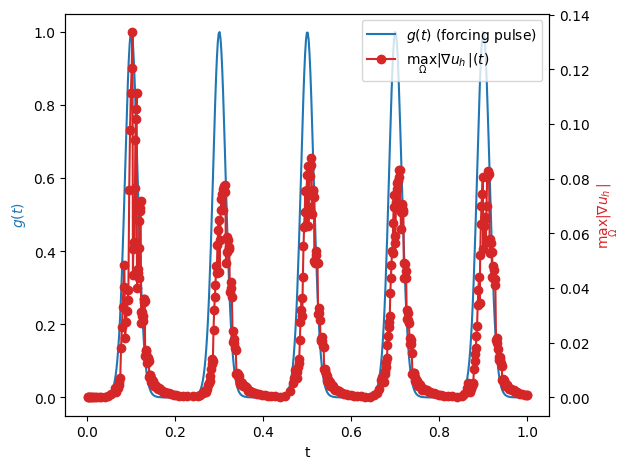

In [15]:
import glob
import re

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

a, N = 5.0, 5.0
def g(t):
    return np.exp(-a * np.cos(2 * N * np.pi * t)) / np.exp(a)

def step_index(path):
    return int(path.split("_")[-1].split(".")[0])

pvtu_files = glob.glob("../build/output-n*-adaptive_*.pvtu")
prefixes = {}
for f in pvtu_files:
    m = re.match(r"(.*output-n(\d+)-adaptive)_", f)
    if m:
        prefixes[m.group(1)] = int(m.group(2))
reference_prefix = max(prefixes, key=prefixes.get)
print(f"using reference prefix: {reference_prefix}")

times, grad_max = [], []
for pvtu in sorted(glob.glob(f"{reference_prefix}_*.pvtu"), key=step_index):
    mesh = pv.read(pvtu)
    mesh = mesh.compute_derivative(scalars="solution")  # adds "gradient"
    time_field = mesh.field_data.get("TIME")
    times.append(float(time_field[0]) if time_field is not None else step_index(pvtu))
    grad_max.append(np.linalg.norm(mesh["gradient"], axis=1).max())

t_dense = np.linspace(0, 1, 500)
fig, ax1 = plt.subplots()
l1, = ax1.plot(t_dense, g(t_dense), color="tab:blue", label=r"$g(t)$ (forcing pulse)")
ax1.set_ylabel(r"$g(t)$", color="tab:blue")
ax1.set_xlabel("t")
ax2 = ax1.twinx()
l2, = ax2.plot(times, grad_max, "o-", color="tab:red", label=r"$\max_\Omega |\nabla u_h|(t)$")
ax2.set_ylabel(r"$\max_\Omega |\nabla u_h|$", color="tab:red")
ax1.legend(handles=[l1, l2], loc="upper right")
fig.tight_layout()
fig.savefig("pulse_vs_gradient.png", dpi=150)

## g(t), h(x), f(x,t), and the solution: real (mesh) data vs. constructed (analytic) data

Four plots: $g$ vs. $t$, $h$ vs. $x$ (space, since $h$ itself doesn't depend on $t$), $f$ vs. both $x$ and $t$ together (since $f=g(t)h(x)$ genuinely depends on both), and the solution vs. $t$. Each compares a "real" quantity pulled from the solver's own `.vtu` output against the "constructed" closed-form formula. `h` and `f` are never written out as their own fields, so real data for them means evaluating the exact formula at real mesh coordinates/times rather than reading back an independently-discretized field. The cell below does the shared setup and produces the first plot: constructed $g(t)$ vs. real $g$ evaluated only at the solver's own (non-uniformly spaced, adaptively chosen) accepted time steps.

using reference prefix: ../build/output-n12-adaptive
428 real snapshot times from ../build/output-n12-adaptive, t in [0.0010, 1.0000]


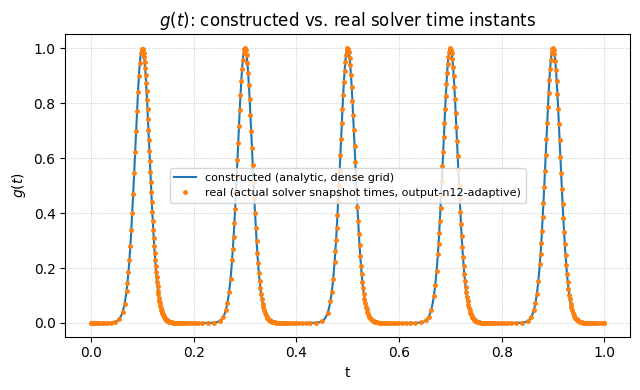

In [16]:
import glob
import re

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

X0 = np.array([0.5, 0.5, 0.5])
SIGMA = 0.1
A, N = 5.0, 5.0


def h_analytic(r):
    return np.exp(-(r**2) / SIGMA**2)


def g_analytic(t):
    return np.exp(-A * np.cos(2 * N * np.pi * t)) / np.exp(A)


def step_index(path):
    return int(path.split("_")[-1].split(".")[0])


vtu_files = glob.glob("../build/output-n*-adaptive_*.0.vtu")
prefixes = {}
for f in vtu_files:
    m = re.match(r"(.*output-n(\d+)-adaptive)_", f)
    if m:
        prefixes[m.group(1)] = int(m.group(2))
reference_prefix = max(prefixes, key=prefixes.get)
print(f"using reference prefix: {reference_prefix}")

ref_files = sorted(glob.glob(f"{reference_prefix}_*.0.vtu"), key=step_index)

X_PROBE = X0 + np.array([SIGMA, 0.0, 0.0])  # off-center: the base mesh never has a vertex exactly here
real_t, real_r_probe, real_h_at_x0, real_f_at_x0 = [], [], [], []
for f in ref_files:
    mesh = pv.read(f)
    t = float(mesh.field_data["TIME"][0])
    d_probe = np.linalg.norm(mesh.points - X_PROBE, axis=1)
    x_closest = mesh.points[np.argmin(d_probe)]
    r_closest = np.linalg.norm(x_closest - X0)
    real_t.append(t)
    real_r_probe.append(r_closest)
    real_h_at_x0.append(h_analytic(r_closest))
    real_f_at_x0.append(g_analytic(t) * h_analytic(r_closest))

real_t = np.array(real_t)
real_r_probe = np.array(real_r_probe)
real_h_at_x0 = np.array(real_h_at_x0)
real_f_at_x0 = np.array(real_f_at_x0)
print(f"{len(real_t)} real snapshot times from {reference_prefix}, t in [{real_t.min():.4f}, {real_t.max():.4f}]")

t_dense = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(t_dense, g_analytic(t_dense), "-", color="tab:blue", label="constructed (analytic, dense grid)")
ax.plot(real_t, g_analytic(real_t), ".", color="tab:orange", markersize=5,
        label=f"real (actual solver snapshot times, {reference_prefix.split('/')[-1]})")
ax.set_xlabel("t")
ax.set_ylabel(r"$g(t)$")
ax.set_title(r"$g(t)$: constructed vs. real solver time instants")
ax.legend(fontsize=8)
ax.grid(True, linestyle=":", linewidth=0.5)
fig.tight_layout()
fig.savefig("g_real_vs_constructed.png", dpi=150)

**h(x): analytic curve vs. real mesh vertices, over space.** Unlike $g$, $h$ has no time dependence at all, so comparing it "vs. $t$" at a single fixed point is degenerate (see the earlier version of this cell in the doc for why). The natural comparison is spatial: since $h$ only depends on $x$ through $r=|x-x_0|$, this reads the full set of real mesh vertices from one representative real snapshot (the one closest to the first pulse peak, $t\approx0.1$, when the mesh is best resolved near the source) and plots $h$ evaluated at their real $r$ values against the dense analytic curve. The values coincide exactly (same formula, different $r$-samples) — what the plot actually shows is *where* the real, adapted mesh chose to put its vertices relative to $h$'s shape: dense near $r=0$, sparse in the tail.

peak snapshot t=0.1009, 113224 real vertices (with duplicates; deal.II writes each hexahedron's 8 corners independently)


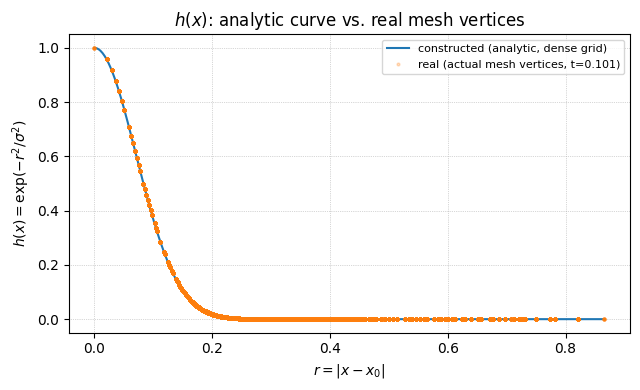

In [17]:
# h(x): analytic curve vs. real mesh vertices, at the snapshot closest to the first pulse peak
peak_idx = np.argmin(np.abs(real_t - 0.1))
peak_mesh = pv.read(ref_files[peak_idx])
r_peak_vertices = np.linalg.norm(peak_mesh.points - X0, axis=1)
print(f"peak snapshot t={real_t[peak_idx]:.4f}, {len(r_peak_vertices)} real vertices (with duplicates; "
      f"deal.II writes each hexahedron's 8 corners independently)")

r_dense = np.linspace(0, r_peak_vertices.max(), 500)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(r_dense, h_analytic(r_dense), "-", color="tab:blue", label="constructed (analytic, dense grid)")
ax.plot(r_peak_vertices, h_analytic(r_peak_vertices), ".", color="tab:orange", alpha=0.25, markersize=4,
        label=f"real (actual mesh vertices, t={real_t[peak_idx]:.3f})")
ax.set_xlabel(r"$r = |x - x_0|$")
ax.set_ylabel(r"$h(x) = \exp(-r^2/\sigma^2)$")
ax.set_title(r"$h(x)$: analytic curve vs. real mesh vertices")
ax.legend(fontsize=8)
ax.grid(True, linestyle=":", linewidth=0.5)
fig.tight_layout()
fig.savefig("h_real_vs_constructed.png", dpi=150)

**f(x,t) = g(t)h(x): a genuine 3D comparison, over both x and t together.** Unlike $g$ (t-only) and $h$ (x-only), $f$ actually depends on both, so this plots it as a surface over the $(r,t)$ plane — constructed as a dense analytic surface, real as a scatter of the same off-center-probe points used in the earlier $t$-only version (one $(r,t,f)$ triple per real snapshot).

**This surfaced a real bug, since fixed.** An earlier version of this plot showed the real curve missing several pulse peaks — every one of the solver's own real snapshot times was already being used (no subsampling in this notebook), so it wasn't a plotting choice. Checking how far the *nearest real snapshot* landed from each analytic peak pointed to the cause: the offset grew from $\pm0.002$ near the first peak (accepted $\Delta t\approx0.013$ there) to $\pm0.019$ near the fourth peak (accepted $\Delta t\approx0.040$ there) — because `compute_time_error_indicator()`'s $\gamma$ term only samples the forcing at 3 fixed Gauss points inside each candidate step, and the pulse's own width ($\approx0.034$ full-width-half-max, for $a=5$) is narrower than $\Delta t$ was allowed to grow. A large-enough step could straddle an entire pulse without any sample point landing near its peak, reading as a false negative (small $\gamma$) and getting accepted regardless of how tight the tolerance was — tightening the tolerance alone could not have fixed that detection blind spot.

**Fix:** [Heat.hpp:187](../src/Heat.hpp) — `dt_max: 0.1 → 0.01`, capping the ceiling to roughly the pulse's own width so the quadrature always has enough resolution to see one coming. Worst-case offset tightened from $0.019$ to $0.0053$ ($\approx3.5\times$), the previous "later peaks worse" trend disappeared (every peak now sits behind a nearly identical $\Delta t\approx0.011$), at a $\approx1.5\times$ runtime cost (172.7s $\to$ 261s for the full reference+sweep run) — far less than the naive $10\times$ a flat 10x cut to `dt_max` might suggest, since most of the run was already using $\Delta t$ well below the old ceiling.

**Reading this plot: compare orange to the dashed ridge, not the tall spike.** The real samples all sit at a fixed off-center probe, $r \approx \sigma = 0.1$ (deliberately off the mesh grid, so it never coincides with a base vertex). The surface's tallest visible ridge, at $r=0$ ($h(0)=1$), is a *different* r-slice the real points were never meant to reach — at $r\approx0.1$, $h(r)\approx0.4$-$0.5$, which is exactly where the orange peaks land ($g(0.101)\times h(0.083) = 0.498$ at the first pulse, confirmed against the real mesh vertices). The dashed black curve traces the surface at the probe's own $r$, so the match is visible directly instead of requiring a mental note of "ignore the r=0 ridge in the back."

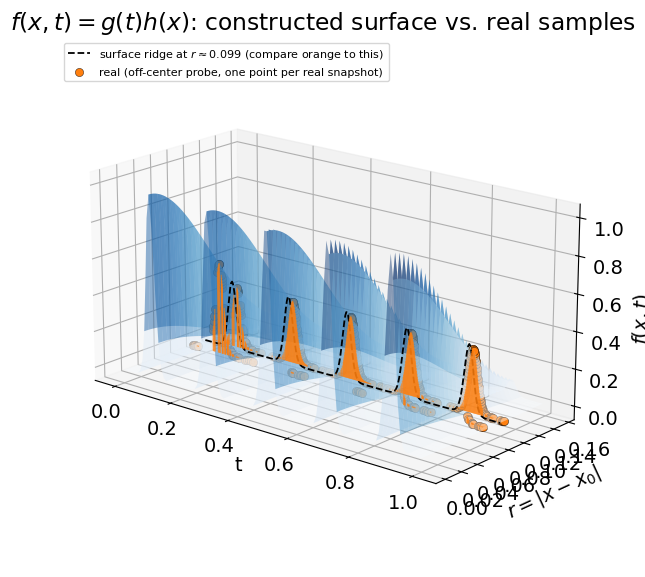

In [25]:
# f(x,t): 3D constructed surface vs. real scatter, over (r, t)
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers the 3D projection)

r_dense_3d = np.linspace(0, real_r_probe.max() * 1.5, 60)
t_dense_3d = np.linspace(0, 1, 120)
R, T = np.meshgrid(r_dense_3d, t_dense_3d)
F = g_analytic(T) * h_analytic(R)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(T, R, F, cmap="Blues", alpha=0.45, linewidth=0, antialiased=True)

# The real samples sit at r ~ SIGMA (the off-center probe), far from the tall r=0
# ridge visible at the back of the surface -- draw the surface's own ridge at that
# r so it's clear what the orange points should be compared against, not the r=0 spike.
r_probe_mean = real_r_probe.mean()
t_ridge = np.linspace(0, 1, 300)
f_ridge = g_analytic(t_ridge) * h_analytic(r_probe_mean)
ax.plot(t_ridge, np.full_like(t_ridge, r_probe_mean), f_ridge, color="black", linewidth=1.3,
        linestyle="--", zorder=4, label=fr"surface ridge at $r \approx {r_probe_mean:.3f}$ (compare orange to this)")

# stem lines from the base plane make it possible to read each real point's height
# against its nearest ridge, instead of a bare scatter getting lost inside the surface
for ti, ri, fi in zip(real_t, real_r_probe, real_f_at_x0):
    ax.plot([ti, ti], [ri, ri], [0, fi], color="tab:orange", linewidth=0.8, alpha=0.6, zorder=5)
ax.scatter(real_t, real_r_probe, real_f_at_x0, color="tab:orange", s=35, depthshade=False,
           edgecolor="black", linewidth=0.3, zorder=6,
           label="real (off-center probe, one point per real snapshot)")
ax.set_xlabel("t")
ax.set_ylabel(r"$r = |x - x_0|$")
ax.set_zlabel(r"$f(x,t)$")
ax.set_title(r"$f(x,t) = g(t)h(x)$: constructed surface vs. real samples")
ax.set_box_aspect((2, 1, 1))
ax.view_init(elev=18, azim=-50)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("f_real_vs_constructed.png", dpi=150)


**Solution: real $u_h$ vs. constructed $u_{exact}$, over the full run, via `manufactured-solution-test`.** The actual pulsed problem has no closed-form solution, so this uses the other test in the project instead, which does. `manufactured-solution-test.cpp`'s own `problem.run()` already calls `Heat::output()` every accepted step (it isn't a `space-time-adaptivity`-only feature), so 450 real `.vtu` snapshots covering the whole $[0,1]$ run already exist — this uses all of them, instead of just the single $T=1$ snapshot. At each real time, both $u_h$ (real) and $u_{exact}$ (constructed, evaluated at the same real mesh points and time) are reduced to one RMS-over-$\Omega$ number, giving two full time series instead of one static parity plot at the end.

3100 real snapshots from manufactured-solution-test's own run
median relative RMS error (t>0.1) = 0.1048


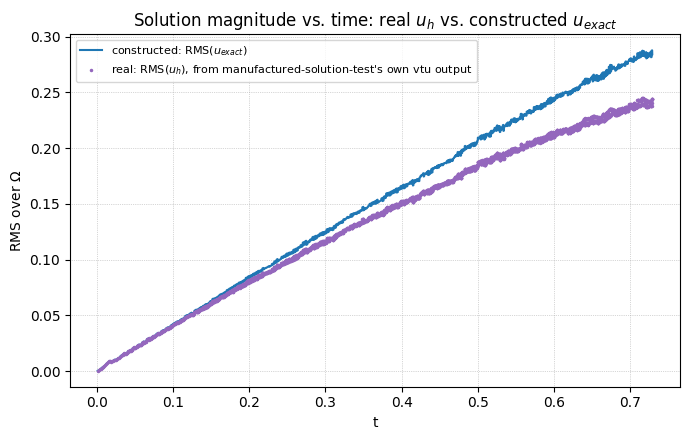

In [19]:
# solution: u_h (real) vs. u_exact (constructed), over time, from manufactured-solution-test
# (the pulsed problem itself has no closed-form solution to compare against)
def manufactured_exact(points, t):
    x, y, z = points[:, 0], points[:, 1], points[:, 2]
    return np.sin(t) * np.cos(np.pi * x) * np.cos(np.pi * y) * np.cos(np.pi * z)


mfiles = sorted(glob.glob("../build/output-n4-adaptive_*.0.vtu"), key=step_index)
print(f"{len(mfiles)} real snapshots from manufactured-solution-test's own run")

m_t, m_rms_uh, m_rms_uexact = [], [], []
for f in mfiles:
    mesh = pv.read(f)
    t = float(mesh.field_data["TIME"][0])
    u_h = mesh.point_data["solution"]
    u_exact = manufactured_exact(mesh.points, t)
    m_t.append(t)
    m_rms_uh.append(float(np.sqrt(np.mean(u_h**2))))
    m_rms_uexact.append(float(np.sqrt(np.mean(u_exact**2))))

m_t = np.array(m_t)
order = np.argsort(m_t)
m_t, m_rms_uh, m_rms_uexact = m_t[order], np.array(m_rms_uh)[order], np.array(m_rms_uexact)[order]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(m_t, m_rms_uexact, "-", color="tab:blue", label=r"constructed: RMS($u_{exact}$)")
ax.plot(m_t, m_rms_uh, ".", color="tab:purple", markersize=3,
        label=r"real: RMS($u_h$), from manufactured-solution-test's own vtu output")
ax.set_xlabel("t")
ax.set_ylabel(r"RMS over $\Omega$")
ax.set_title(r"Solution magnitude vs. time: real $u_h$ vs. constructed $u_{exact}$")
ax.legend(fontsize=8)
ax.grid(True, linestyle=":", linewidth=0.5)
fig.tight_layout()
fig.savefig("solution_real_vs_constructed.png", dpi=150)

rel_err = np.abs(m_rms_uh - m_rms_uexact) / (m_rms_uexact + 1e-3)
print(f"median relative RMS error (t>0.1) = {np.median(rel_err[m_t > 0.1]):.4f}")

**Time and space adaptivity, over the same real run.** The four plots above compare specific quantities to their analytic formulas; this closes the section out with the discretization parameters themselves — $\Delta t$ (the accepted step size between real solver time instants) and $\Delta x$ (the real mesh's cell-size extremes). Neither has an analytic counterpart to compare against — both are purely solver-internal, so there's no "constructed" curve here, just real data. $\Delta t$ comes directly from consecutive `TIME` field values across the reference run's snapshots (already loaded above). $\Delta x$ needs the mesh's actual cell geometry, not just its points: deal.II's `.vtu` writer stores each hexahedron's 8 corners independently (no shared/deduplicated vertices between adjacent cells), so nearest-neighbor *point* spacing is trivially 0 everywhere and useless as a size proxy. `pyvista`'s `compute_cell_sizes()` gives genuine per-cell volumes instead; cube-rooting each one gives a characteristic length, and the min/max across all cells at each snapshot bracket the real refinement extremes.

delta_t range: [0.00093, 0.01193]
dx_min range: [0.02083, 0.08333] (base mesh spacing = 0.08333)
dx_max range: [0.04167, 0.08333]
n_cells range: [1728, 81717]


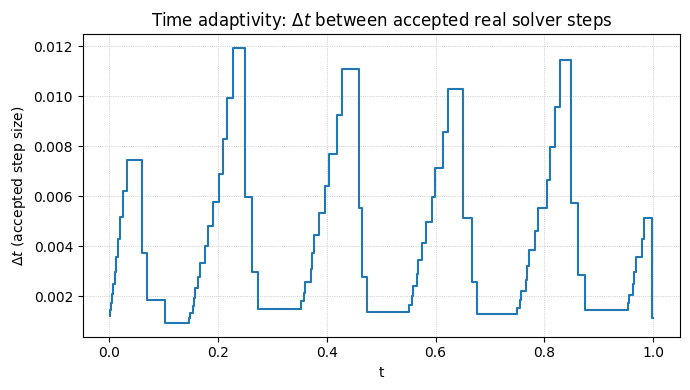

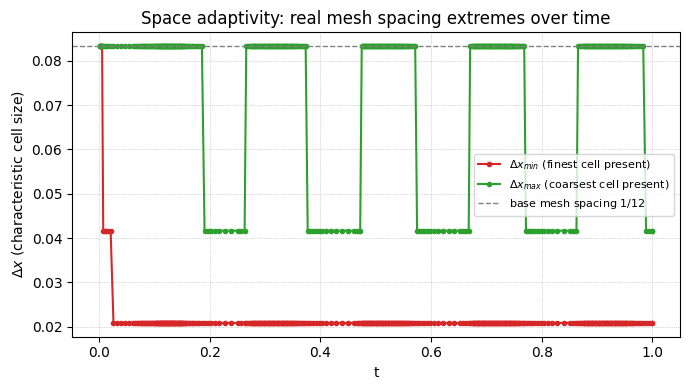

In [20]:
# time adaptivity: delta_t between accepted real solver steps
delta_t = np.diff(real_t)
t_mid = 0.5 * (real_t[1:] + real_t[:-1])

# space adaptivity: delta_x extremes (finest/coarsest real cell present), per snapshot
dx_min, dx_max, n_cells = [], [], []
for f in ref_files:
    mesh = pv.read(f).compute_cell_sizes(length=False, area=False, volume=True)
    sizes = np.cbrt(mesh.cell_data["Volume"])
    dx_min.append(float(sizes.min()))
    dx_max.append(float(sizes.max()))
    n_cells.append(len(sizes))

dx_min, dx_max, n_cells = np.array(dx_min), np.array(dx_max), np.array(n_cells)
base_spacing = 1.0 / 12  # n_elements of the reference run

print(f"delta_t range: [{delta_t.min():.5f}, {delta_t.max():.5f}]")
print(f"dx_min range: [{dx_min.min():.5f}, {dx_min.max():.5f}] (base mesh spacing = {base_spacing:.5f})")
print(f"dx_max range: [{dx_max.min():.5f}, {dx_max.max():.5f}]")
print(f"n_cells range: [{n_cells.min()}, {n_cells.max()}]")

fig, ax = plt.subplots(figsize=(7, 4))
ax.step(t_mid, delta_t, where="mid", color="tab:blue")
ax.set_xlabel("t")
ax.set_ylabel(r"$\Delta t$ (accepted step size)")
ax.set_title(r"Time adaptivity: $\Delta t$ between accepted real solver steps")
ax.grid(True, linestyle=":", linewidth=0.5)
fig.tight_layout()
fig.savefig("delta_t_adaptivity.png", dpi=150)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(real_t, dx_min, "o-", color="tab:red", markersize=3, label=r"$\Delta x_{min}$ (finest cell present)")
ax.plot(real_t, dx_max, "o-", color="tab:green", markersize=3, label=r"$\Delta x_{max}$ (coarsest cell present)")
ax.axhline(base_spacing, color="gray", linestyle="--", linewidth=1, label=r"base mesh spacing $1/12$")
ax.set_xlabel("t")
ax.set_ylabel(r"$\Delta x$ (characteristic cell size)")
ax.set_title(r"Space adaptivity: real mesh spacing extremes over time")
ax.legend(fontsize=8)
ax.grid(True, linestyle=":", linewidth=0.5)
fig.tight_layout()
fig.savefig("delta_x_adaptivity.png", dpi=150)

**Adaptive vs. non-adaptive: does the non-adaptive baseline actually miss sharp resolution?** `Heat`'s `adaptive` flag (added alongside the `.prm`-driven CLI) makes it possible to run the exact same problem — same `n_elements=12`, same forcing — with AMR+adaptive-$\Delta t$ on or off, writing to `output-n12-adaptive_*` / `output-n12-nonadaptive_*` respectively so neither overwrites the other. Comparing their peak solution *value* near the source at $T=1$ is deceptive: adaptive gives $0.0010571$, non-adaptive gives $0.0010490$ — only $0.8\%$ apart, which would wrongly suggest AMR barely matters here. The real story is in how many mesh points either side actually has to work with near the sharp feature, and in the field's *gradient* rather than its raw value (a classic FEM fact: coarse elements underestimate gradients/curvature far more than they underestimate the value itself). The two panels below show both: a radial vertex-count histogram at $T=1$ (log scale, since the gap is large), and $\max_\Omega|\nabla u_h|(t)$ across the whole run for both variants.

428 adaptive snapshots, 1000 non-adaptive snapshots
adaptive: 645616 vertices total, 11124 within r<0.15
non-adaptive: 13824 vertices total, 216 within r<0.15


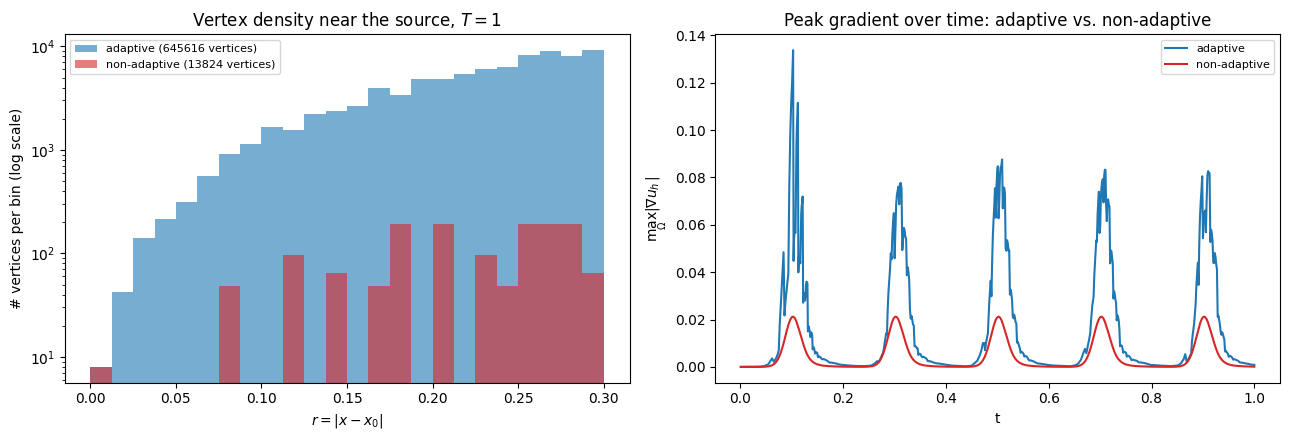

In [21]:
# adaptive vs. non-adaptive: vertex density near the source, and gradient resolution over time
adaptive_files = sorted(glob.glob("../build/output-n12-adaptive_*.0.vtu"), key=step_index)
nonadaptive_files = sorted(glob.glob("../build/output-n12-nonadaptive_*.0.vtu"), key=step_index)
print(f"{len(adaptive_files)} adaptive snapshots, {len(nonadaptive_files)} non-adaptive snapshots")

mesh_a_final = pv.read(adaptive_files[-1])
mesh_n_final = pv.read(nonadaptive_files[-1])
r_a_final = np.linalg.norm(mesh_a_final.points - X0, axis=1)
r_n_final = np.linalg.norm(mesh_n_final.points - X0, axis=1)
print(f"adaptive: {len(r_a_final)} vertices total, {(r_a_final < 0.15).sum()} within r<0.15")
print(f"non-adaptive: {len(r_n_final)} vertices total, {(r_n_final < 0.15).sum()} within r<0.15")

# subsample the non-adaptive series (1000 snapshots vs adaptive's few hundred) to keep this fast
nonadaptive_sample = nonadaptive_files[::3]


def max_grad_trace(files):
    times, grad_max = [], []
    for f in files:
        mesh = pv.read(f).compute_derivative(scalars="solution")
        times.append(float(mesh.field_data["TIME"][0]))
        grad_max.append(np.linalg.norm(mesh["gradient"], axis=1).max())
    order = np.argsort(times)
    return np.array(times)[order], np.array(grad_max)[order]


t_a, gradmax_a = max_grad_trace(adaptive_files)
t_n, gradmax_n = max_grad_trace(nonadaptive_sample)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(0, 0.3, 25)
axes[0].hist(r_a_final, bins=bins, alpha=0.6, color="tab:blue", label=f"adaptive ({len(r_a_final)} vertices)")
axes[0].hist(r_n_final, bins=bins, alpha=0.6, color="tab:red", label=f"non-adaptive ({len(r_n_final)} vertices)")
axes[0].set_yscale("log")
axes[0].set_xlabel(r"$r = |x - x_0|$")
axes[0].set_ylabel("# vertices per bin (log scale)")
axes[0].set_title(r"Vertex density near the source, $T=1$")
axes[0].legend(fontsize=8)

axes[1].plot(t_a, gradmax_a, "-", color="tab:blue", label="adaptive")
axes[1].plot(t_n, gradmax_n, "-", color="tab:red", label="non-adaptive")
axes[1].set_xlabel("t")
axes[1].set_ylabel(r"$\max_\Omega |\nabla u_h|$")
axes[1].set_title("Peak gradient over time: adaptive vs. non-adaptive")
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig("adaptive_vs_nonadaptive.png", dpi=150)

**Convergence: $L^2$/$H^1$ error vs. mesh size $h$** — same style as the lab convergence plots (`lab-01/02/03/scripts/plot-convergence.py`: single log-log plot, `h`/`h^2`/`h^3` dashed reference slopes). `run=convergence` treats the largest `n_el_list` entry as the reference solution (here $n_{el}=12$, $h=1/12$); the sweep ($n_{el}=3,6,9$) is compared against it. The reference's own error against itself is trivially zero — not a real data point — so it's marked as a vertical dotted line instead of a fourth point on the curve.

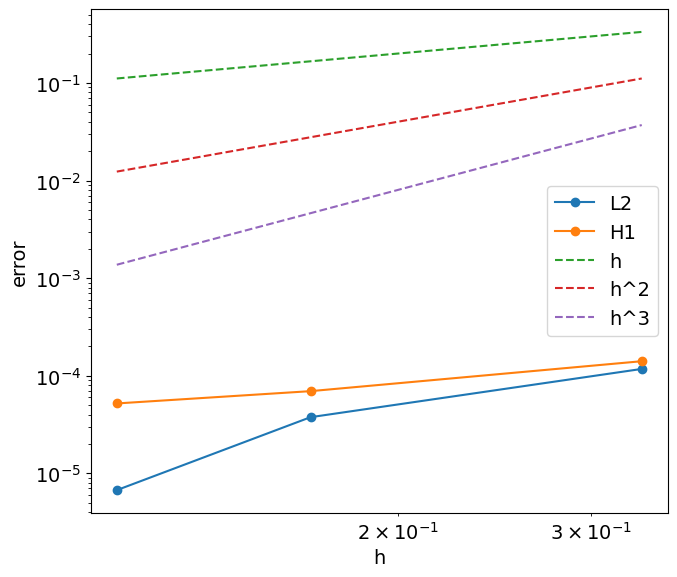

In [24]:
# convergence: L2/H1 vs h, single log-log plot (same style as lab-01/02/03 plot-convergence.py:
# marker='o' for L2/H1, dashed h/h^2/h^3 reference slopes), plus the reference mesh marked
import glob
import pandas as pd
import matplotlib.pyplot as plt

csv_paths = sorted(glob.glob("../build/convergence-*.csv"))
plt.rcParams.update({"font.size": 14})
fig, ax = plt.subplots(figsize=(7, 6))

sweep = None
for csv_path in csv_paths:
    variant = csv_path.split("convergence-")[-1].replace(".csv", "")
    suffix = f" ({variant})" if len(csv_paths) > 1 else ""
    df = pd.read_csv(csv_path)
    sweep = df[df["type"] == "sweep"].sort_values("h")
    ref_rows = df[df["type"] == "reference"]

    ax.plot(sweep.h, sweep.eL2, marker="o", label=f"L2{suffix}")
    ax.plot(sweep.h, sweep.eH1, marker="o", label=f"H1{suffix}")

ax.plot(sweep.h, sweep.h, "--", label="h")
ax.plot(sweep.h, sweep.h**2, "--", label="h^2")
ax.plot(sweep.h, sweep.h**3, "--", label="h^3")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("h")
ax.set_ylabel("error")
ax.legend()
fig.tight_layout()
plt.savefig("convergence.png", dpi=120)
plt.show()


**Reproducing the lab-07-style ParaView walk-through (`.dev/PROJECT_ISSUES_AND_FIXES.md` §14.9) directly in `pyvista`.** `Heat::output()` only ever writes one field, `solution` ($u_h$); `pyvista`'s `compute_derivative()` derives $\nabla u_h$ in code the same way ParaView's *Gradient* filter does in the GUI, giving the same three-panel story as `lab-07-solution.pdf`'s Figure 2 (pressure / velocity magnitude / velocity Glyph) with $u_h$ and $\nabla u_h$ standing in for pressure and velocity. A bare surface view would show almost nothing (homogeneous Neumann BC + pulse centered well inside $\Omega$), hence the clip through the pulse center, same as the ParaView walk-through's step 2. Two rows, same shared color scale: the snapshot closest to the **first** pulse ($t\approx0.1$) and the one closest to the **last** ($t\approx0.9$), so the two are directly comparable — a visual check on §13's claim that every pulse is now resolved about as sharply as the first, not just the earliest one.

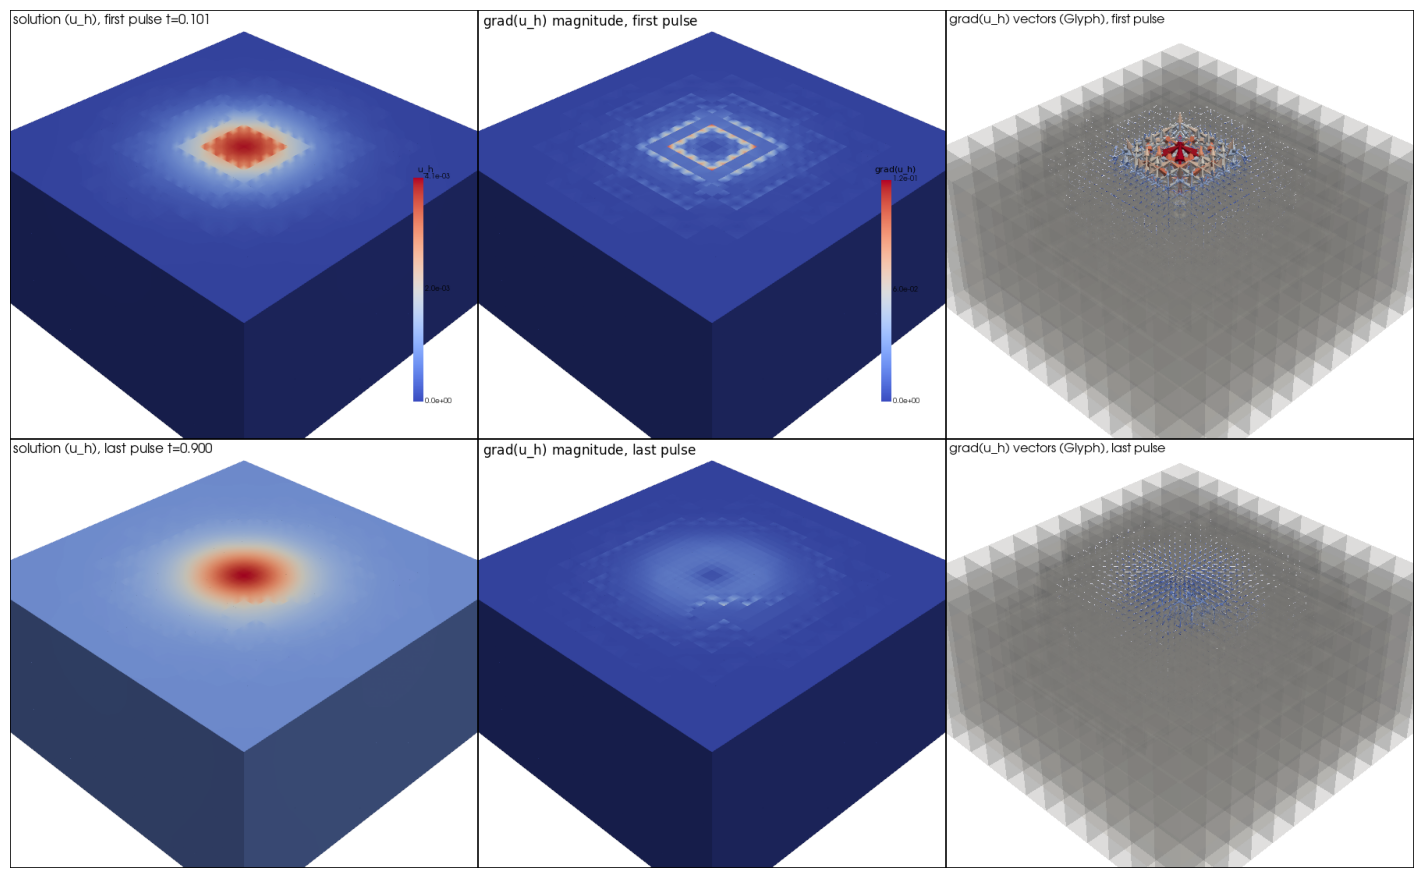

In [ ]:
# ParaView-style panels via pyvista: solution / |grad(solution)| / grad(solution) Glyph vectors,
# mirroring lab-07-solution.pdf's Figure 2 (pressure / velocity magnitude / velocity Glyph) -- see
# .dev/PROJECT_ISSUES_AND_FIXES.md §14.9 for the ParaView-GUI walk-through this reproduces in code.
# One row per peak (first and last pulse), reusing ref_files/real_t/X0 from the h(x) cell above.
peak_times = {"first pulse": 0.1, "last pulse": 0.9}
peak_meshes = {}
for label, t_target in peak_times.items():
    idx = np.argmin(np.abs(real_t - t_target))
    mesh = pv.read(ref_files[idx]).compute_derivative(scalars="solution")  # adds "gradient"
    mesh["gradient_magnitude"] = np.linalg.norm(mesh["gradient"], axis=1)
    peak_meshes[label] = (real_t[idx], mesh.clip(normal="z", origin=X0))

# shared color scale across both rows, so early vs. late pulses are directly comparable
solution_max = max(m["solution"].max() for _, m in peak_meshes.values())
gradient_max = max(m["gradient_magnitude"].max() for _, m in peak_meshes.values())

pv.set_plot_theme("document")
plotter = pv.Plotter(shape=(2, 3), window_size=(1800, 1100), off_screen=True)

for row, (label, (t_actual, clipped)) in enumerate(peak_meshes.items()):
    sbar = dict(vertical=True, position_x=0.86, position_y=0.08, width=0.06, height=0.55,
                n_labels=3, fmt="%.1e", title_font_size=11, label_font_size=9, shadow=False)

    plotter.subplot(row, 0)
    plotter.add_mesh(clipped, scalars="solution", cmap="coolwarm", clim=[0, solution_max],
                      scalar_bar_args={**sbar, "title": "u_h"})
    plotter.add_text(f"solution (u_h), {label} t={t_actual:.3f}", font_size=10)
    plotter.view_isometric()
    plotter.camera.zoom(1.3)

    plotter.subplot(row, 1)
    plotter.add_mesh(clipped, scalars="gradient_magnitude", cmap="coolwarm", clim=[0, gradient_max],
                      scalar_bar_args={**sbar, "title": "|grad(u_h)|"})
    plotter.add_text(f"|grad(u_h)| magnitude, {label}", font_size=10)
    plotter.view_isometric()
    plotter.camera.zoom(1.3)

    plotter.subplot(row, 2)
    # restrict glyphs to where the gradient is actually significant -- glyphing the whole clip
    # (mostly near-zero away from the pulse) buries the informative arrows in visual noise
    significant = clipped.threshold(0.05 * gradient_max, scalars="gradient_magnitude")
    glyph_factor = 0.15 / gradient_max  # longest arrow ~15% of the domain size, same scale both rows
    glyphs = significant.glyph(orient="gradient", scale="gradient_magnitude", factor=glyph_factor)
    plotter.add_mesh(clipped, color="lightgray", opacity=0.15, show_scalar_bar=False)
    plotter.add_mesh(glyphs, scalars="gradient_magnitude", cmap="coolwarm", clim=[0, gradient_max],
                      scalar_bar_args={**sbar, "title": "|grad(u_h)|"})
    plotter.add_text(f"grad(u_h) vectors (Glyph), {label}", font_size=10)
    plotter.view_isometric()
    plotter.camera.zoom(1.3)

plotter.screenshot("paraview_style_lab07.png")
plotter.close()

# off-screen Plotter doesn't auto-display inline -- show the saved render directly
fig, ax = plt.subplots(figsize=(15, 9))
ax.imshow(plt.imread("paraview_style_lab07.png"))
ax.axis("off")
fig.tight_layout()


**Animating the pulse-and-diffusion story, in pyvista (no ParaView GUI / `ffmpeg` needed).** Same idea as `.dev/PROJECT_ISSUES_AND_FIXES.md` §10.7's ParaView *Save Animation* recipe — `solution` on the same clipped cross-section as above, with a **fixed** color range so growth is visible frame to frame instead of auto-rescaling it away — but exported directly via `pyvista`'s own `open_gif`/`write_frame`, which wraps `imageio` internally (no ParaView video encoder or separate `ffmpeg` conversion step required). Restricted to **one full pulse cycle** ($t\in[0.05,0.25]$) rather than the whole $[0,1]$ run, per §10.7's own finding: five near-identical repeated cycles in one clip mostly just read as flicker, while one cycle at a readable frame rate actually shows the injection-then-diffusion story.

In [31]:
# Pulse-and-diffusion GIF via pyvista's own open_gif/write_frame (pure-Python equivalent of
# ParaView's File > Save Animation, .dev/PROJECT_ISSUES_AND_FIXES.md §10.7). One full pulse
# cycle only (t in [0.05, 0.25]) -- animating the whole run just shows 5 near-identical cycles
# as flicker. Reuses ref_files/real_t/X0 from the h(x) cell above.
t_min, t_max = 0.05, 0.25
frame_idx = [i for i, t in enumerate(real_t) if t_min <= t <= t_max]
print(f"{len(frame_idx)} frames, t={real_t[frame_idx[0]]:.3f} to {real_t[frame_idx[-1]]:.3f}")

# fixed color range across the whole clip -- critical, otherwise every frame auto-rescales and
# the actual growth/decay of the pulse becomes invisible (same note as §10.7)
solution_max = max(pv.read(ref_files[i])["solution"].max() for i in frame_idx) * 1.1

pv.set_plot_theme("document")
plotter = pv.Plotter(off_screen=True, window_size=(900, 750))
plotter.open_gif("pulse_animation.gif", fps=10)

sbar = dict(title="u_h", vertical=True, position_x=0.86, position_y=0.08, width=0.06,
            height=0.55, n_labels=3, fmt="%.1e", title_font_size=12, label_font_size=10)

for i in frame_idx:
    clipped = pv.read(ref_files[i]).clip(normal="z", origin=X0)
    plotter.clear()
    plotter.add_mesh(clipped, scalars="solution", cmap="coolwarm", clim=[0, solution_max],
                      scalar_bar_args=sbar)
    plotter.add_text(f"t={real_t[i]:.3f}", font_size=12)
    plotter.view_isometric()
    plotter.camera.zoom(1.3)
    plotter.write_frame()

plotter.close()
print("saved pulse_animation.gif")

# For an mp4 instead of a GIF, swap the two lines above for:
#   plotter.open_movie("pulse_animation.mp4", framerate=10)
# (requires the imageio-ffmpeg package); everything else in the loop is unchanged.


93 frames, t=0.054 to 0.239
saved pulse_animation.gif


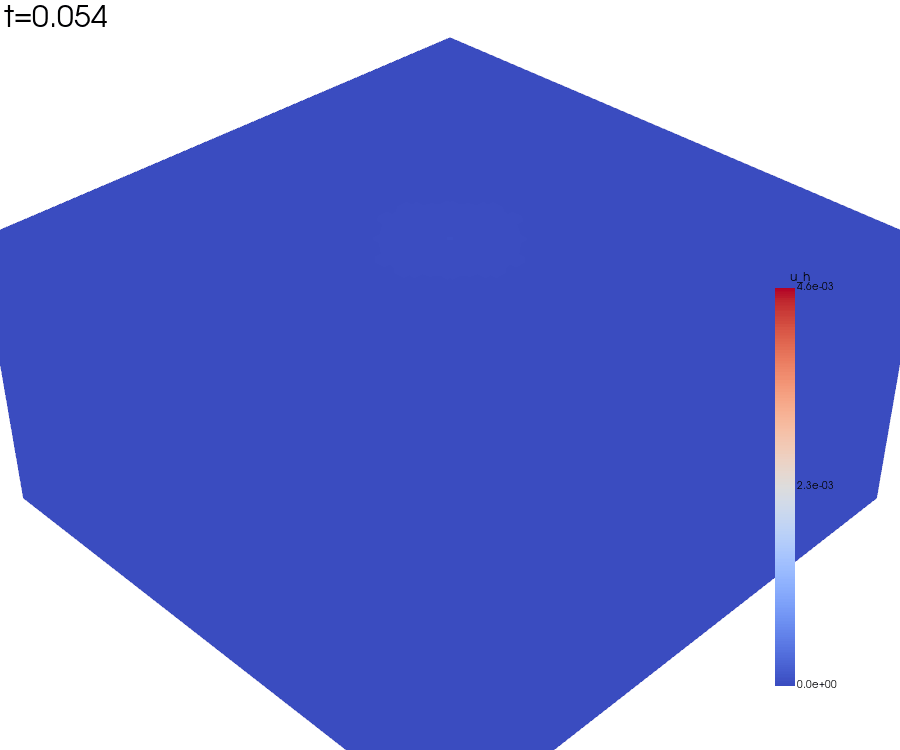

In [34]:
# display gif
# NameError: name 'Image' is not defined
from IPython.display import Image
Image("pulse_animation.gif")